# 08 — Exploratory analysis of AlphaEarth embeddings

**Research brief §2.** Analyze whether different building categories exhibit identifiable structure in embedding space **before** heavier supervised models.

**Methods.**
1. PCA
2. UMAP (incl. per-region residential vs non-residential + 2D LR boundary)
3. t-SNE
4. Overture footprints on the AlphaEarth 10 m grid
5. Clustering (KMeans) vs labels
6. Inter-class / intra-class distances
7. Nearest-neighbor retrieval
8. Embedding similarity (class centroids)

**Data.** `outputs/building_type_dataset/dataset.parquet` (64-D AlphaEarth 2024 @ centroid + high-precision Overture labels).

**Outputs.** `outputs/embedding_eda/`

**Requires.** `pip install -r requirements.txt` (includes `umap-learn`). PCA–similarity cells need no Earth Engine. The Overture overlay cell needs EE auth.


## Setup

In [4]:
from __future__ import annotations

import io
import json
import os
import warnings
import urllib.request as urlreq
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.patches import Rectangle
from PIL import Image
from shapely import wkt as shapely_wkt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder, normalize

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:0.3f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

DATA = ROOT / "outputs" / "building_type_dataset" / "dataset.parquet"
OUT = ROOT / "outputs" / "embedding_eda"
OUT.mkdir(parents=True, exist_ok=True)

BANDS = [f"A{i:02d}" for i in range(64)]
LABEL_ORDER = [
    "single_family",
    "multi_family",
    "education",
    "medical",
    "retail",
    "office",
    "hotel",
    "industrial",
    "religious",
    "civic",
]
RANDOM_STATE = 42

# Distinct colors for 10 classes
COLORS = {
    "single_family": "#4C78A8",
    "multi_family": "#72B7B2",
    "education": "#54A24B",
    "medical": "#E45756",
    "retail": "#F58518",
    "office": "#B279A2",
    "hotel": "#FF9DA6",
    "industrial": "#9D755D",
    "religious": "#BAB0AC",
    "civic": "#EECA3B",
}

print("DATA:", DATA, "exists=", DATA.exists())
print("OUT:", OUT)


DATA: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/building_type_dataset/dataset.parquet exists= True
OUT: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/embedding_eda


**Result.** Dataset found at `outputs/building_type_dataset/dataset.parquet`. Figures and tables will land in `outputs/embedding_eda/`.


## 1. Load embeddings + labels

AlphaEarth vectors are unit-length; we still L2-normalize for cosine ≡ dot product.


In [5]:
df = pd.read_parquet(DATA)
assert set(BANDS).issubset(df.columns)
assert df[BANDS].notna().all().all()

X_raw = df[BANDS].to_numpy(dtype=np.float64)
X = normalize(X_raw, norm="l2")
y = df["label"].astype(str).to_numpy()
regions = df["region"].astype(str).to_numpy()

enc = LabelEncoder().fit(LABEL_ORDER)
y_id = enc.transform(y)

print(f"n={len(df)}  dim={X.shape[1]}  classes={len(LABEL_ORDER)}")
print(f"L2 norms (raw): mean={np.linalg.norm(X_raw, axis=1).mean():.4f}")
print(df["label"].value_counts().reindex(LABEL_ORDER).to_string())


n=11280  dim=64  classes=10
L2 norms (raw): mean=1.0001
label
single_family    1987
multi_family     1102
education        1840
medical           594
retail           1616
office            756
hotel             539
industrial       1287
religious         802
civic             757


**Result.** **11,280** buildings × **64-D** AlphaEarth vectors. Raw L2 norms ≈ **1.00** (unit-length as advertised). Ten classes, unbalanced: single_family 1,987 and education 1,840 vs hotel 539 and medical 594.


## 2. PCA

Linear view of variance. If classes separate here, structure is strong; if not, nonlinear methods / distances still matter.


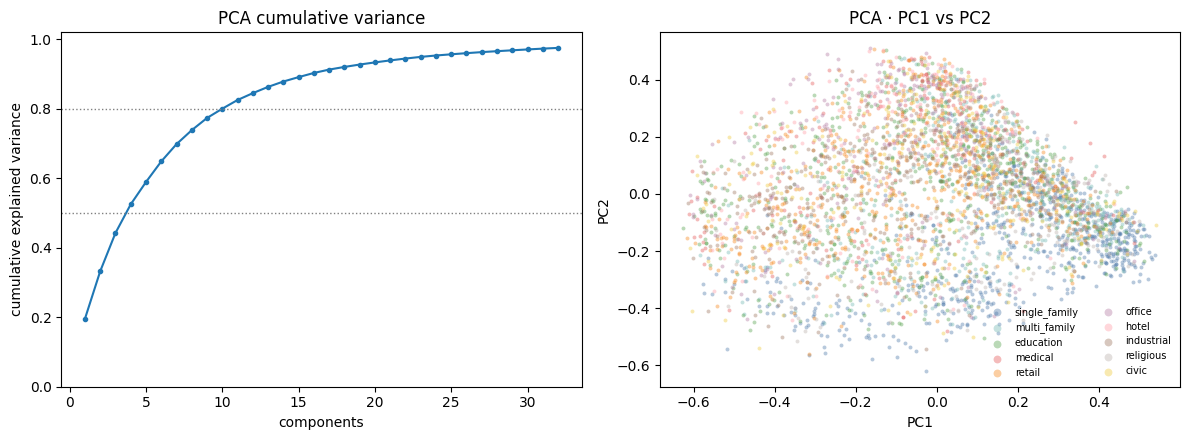

PC1–2 variance: 33.2%
PC1–10 variance: 80.0%


In [6]:
pca = PCA(n_components=min(32, X.shape[1]), random_state=RANDOM_STATE)
Z_pca = pca.fit_transform(X)
var = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(np.arange(1, len(var) + 1), np.cumsum(var), marker="o", ms=3)
axes[0].axhline(0.5, color="gray", ls=":", lw=1)
axes[0].axhline(0.8, color="gray", ls=":", lw=1)
axes[0].set_xlabel("components")
axes[0].set_ylabel("cumulative explained variance")
axes[0].set_title("PCA cumulative variance")
axes[0].set_ylim(0, 1.02)

# PC1–PC2 scatter (subsample for clarity)
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(df), size=min(4000, len(df)), replace=False)
for lab in LABEL_ORDER:
    m = y[idx] == lab
    axes[1].scatter(
        Z_pca[idx][m, 0],
        Z_pca[idx][m, 1],
        s=8,
        alpha=0.4,
        c=COLORS[lab],
        label=lab,
        linewidths=0,
    )
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA · PC1 vs PC2")
axes[1].legend(markerscale=2, fontsize=7, frameon=False, loc="best", ncol=2)

fig.tight_layout()
fig.savefig(OUT / "pca_overview.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"PC1–2 variance: {100 * var[:2].sum():.1f}%")
print(f"PC1–10 variance: {100 * var[:10].sum():.1f}%")
pd.Series(var, index=[f"PC{i+1}" for i in range(len(var))]).head(10).to_frame("explained_var").to_csv(
    OUT / "pca_variance.csv"
)


**Takeaway — PCA.** The first two PCs hold only **33%** of variance; the first **10** hold **80%**. The PC1–PC2 scatter is **one mixed cloud** — no clean class blobs. Linear 2-D views are not enough; type signal, if present, lives in higher dimensions or local neighborhoods.


## 3. UMAP

Nonlinear neighborhood embedding — better for visual cluster structure than PCA when classes mix linearly.


/home/kv133/Alpha-Earth-Embeddings-Research/.venv/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


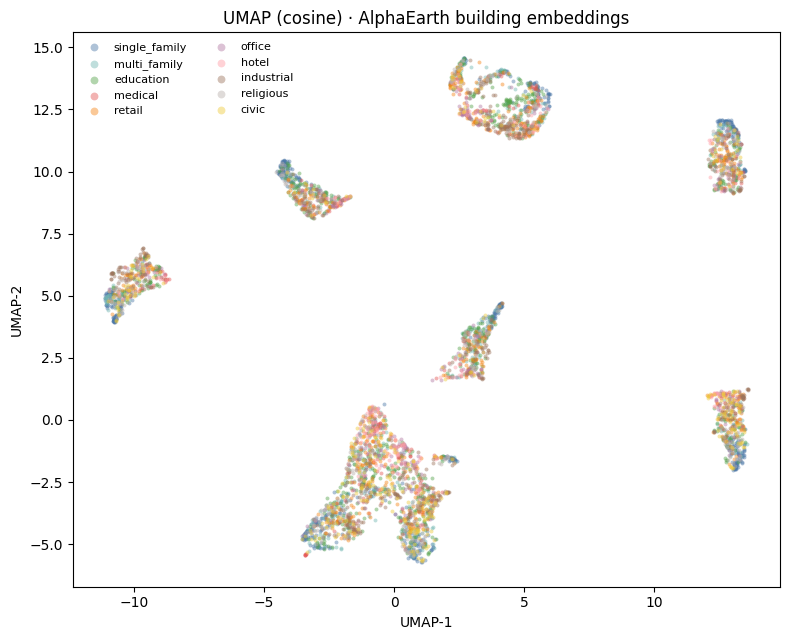

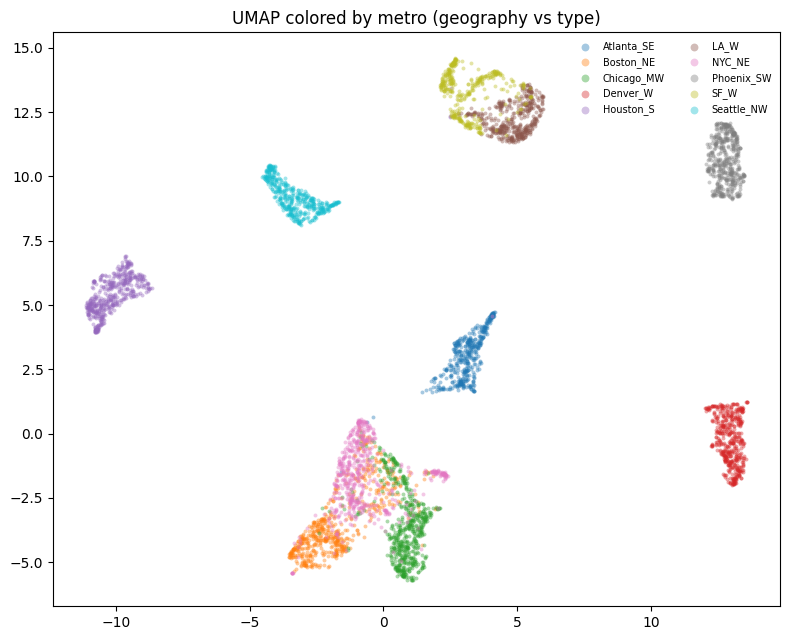

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/embedding_eda/embedding_2d.parquet


In [7]:
try:
    import umap
except ImportError as e:
    raise ImportError("Install umap-learn: pip install umap-learn") from e

# Fit on full set; plot a subsample for readability
umap_model = umap.UMAP(
    n_neighbors=30,
    min_dist=0.1,
    metric="cosine",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
Z_umap = umap_model.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6.5))
idx = rng.choice(len(df), size=min(5000, len(df)), replace=False)
for lab in LABEL_ORDER:
    m = y[idx] == lab
    ax.scatter(
        Z_umap[idx][m, 0],
        Z_umap[idx][m, 1],
        s=8,
        alpha=0.45,
        c=COLORS[lab],
        label=lab,
        linewidths=0,
    )
ax.set_title("UMAP (cosine) · AlphaEarth building embeddings")
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
ax.legend(markerscale=2, fontsize=8, frameon=False, loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUT / "umap_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

# Same UMAP colored by region (geography leak check)
fig, ax = plt.subplots(figsize=(8, 6.5))
region_list = sorted(df["region"].unique())
cmap = plt.cm.tab10(np.linspace(0, 1, len(region_list)))
region_color = {r: cmap[i] for i, r in enumerate(region_list)}
for r in region_list:
    m = regions[idx] == r
    ax.scatter(
        Z_umap[idx][m, 0],
        Z_umap[idx][m, 1],
        s=8,
        alpha=0.4,
        c=[region_color[r]],
        label=r,
        linewidths=0,
    )
ax.set_title("UMAP colored by metro (geography vs type)")
ax.legend(markerscale=2, fontsize=7, frameon=False, loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUT / "umap_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

# Persist coordinates for reuse
umap_df = df[["id", "label", "region"]].copy()
umap_df["umap_1"] = Z_umap[:, 0]
umap_df["umap_2"] = Z_umap[:, 1]
umap_df["pc1"] = Z_pca[:, 0]
umap_df["pc2"] = Z_pca[:, 1]
umap_df.to_parquet(OUT / "embedding_2d.parquet", index=False)
print("Wrote", OUT / "embedding_2d.parquet")


**Takeaway — UMAP.** Colored by **label**, you see islands but each island is a mix of types. Colored by **metro**, those same islands snap to cities (Houston / Denver / Seattle sit apart; SF+LA pair; NYC–Boston–Chicago overlap). **Place dominates type** in the embedding neighborhood graph. That is why leave-one-region-out is the honest test.


### UMAP — one region per panel (+ LR boundary)

Same global UMAP coordinates, one city per panel. Blue = residential (`single_family` / `multi_family`), orange = non-residential.
Black curve = **logistic regression decision boundary fit in the 2D UMAP plane** (not a 64-D probe). Soft blue/red wash is predicted P(residential). Panel titles include in-UMAP macro-F1.

This matches the CNN week-2 panel style (`outputs/week2_cnn_bbox/umap_cnn_by_region_panels_residential_boundary.png`) for a direct centroid-vs-patch comparison.

In [ ]:
from matplotlib.lines import Line2D
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

# Reuse cached global UMAP coords + binary residential flag from the dataset
umap_resi = pd.read_parquet(OUT / "embedding_2d.parquet")[["id", "label", "region", "umap_1", "umap_2"]].copy()
umap_resi = umap_resi.merge(df[["id", "y_res"]], on="id", how="inner")
umap_resi["y_res"] = umap_resi["y_res"].astype(int)

RES_COLORS = {1: "#2c7fb8", 0: "#d95f0e"}
RES_LABELS = {1: "residential", 0: "non-residential"}


def fit_umap_lr_boundary(sub: pd.DataFrame):
    X2 = sub[["umap_1", "umap_2"]].to_numpy(dtype=np.float64)
    yr = sub["y_res"].to_numpy(dtype=int)
    if len(np.unique(yr)) < 2 or min((yr == 0).sum(), (yr == 1).sum()) < 5:
        return None
    pipe = Pipeline(
        [
            ("sc", StandardScaler()),
            ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
        ]
    )
    pipe.fit(X2, yr)
    f1 = float(f1_score(yr, pipe.predict(X2), average="macro"))
    return pipe, f1


def plot_region_resi_boundary(ax, sub: pd.DataFrame, title: str, s: int = 12, legend: bool = True):
    for val in (1, 0):
        m = sub["y_res"] == val
        ax.scatter(
            sub.loc[m, "umap_1"],
            sub.loc[m, "umap_2"],
            s=s,
            alpha=0.75,
            c=RES_COLORS[val],
            edgecolors="none",
            zorder=2,
        )

    fitted = fit_umap_lr_boundary(sub)
    f1 = None
    if fitted is not None:
        pipe, f1 = fitted
        x0, x1 = sub["umap_1"].min(), sub["umap_1"].max()
        y0, y1 = sub["umap_2"].min(), sub["umap_2"].max()
        pad_x = 0.05 * (x1 - x0 + 1e-6)
        pad_y = 0.05 * (y1 - y0 + 1e-6)
        xx, yy = np.meshgrid(
            np.linspace(x0 - pad_x, x1 + pad_x, 300),
            np.linspace(y0 - pad_y, y1 + pad_y, 300),
        )
        zz = pipe.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
        ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 11), cmap="RdYlBu", alpha=0.22, zorder=0)
        cs = ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.8, zorder=3)
        ax.clabel(cs, fmt={0.5: "LR P=0.5"}, inline=True, fontsize=7)
        title = f"{title} · in-UMAP LR F1={f1:.2f}"

    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal", adjustable="datalim")
    if legend:
        handles = [
            Line2D([0], [0], marker="o", color="w", markerfacecolor=RES_COLORS[1], markersize=7, label="residential"),
            Line2D([0], [0], marker="o", color="w", markerfacecolor=RES_COLORS[0], markersize=7, label="non-residential"),
            Line2D([0], [0], color="k", lw=1.8, label="LR boundary"),
        ]
        ax.legend(handles=handles, fontsize=7, frameon=False, loc="best")
    return f1


region_list = sorted(umap_resi["region"].unique())
ncols, nrows = 5, int(np.ceil(len(region_list) / 5))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3.4 * nrows), squeeze=False)
f1_by_region = {}
for ax, region in zip(axes.ravel(), region_list):
    f1_by_region[region] = plot_region_resi_boundary(
        ax, umap_resi[umap_resi["region"] == region], region, s=10, legend=True
    )
for ax in axes.ravel()[len(region_list) :]:
    ax.axis("off")

fig.suptitle(
    "AlphaEarth UMAP by region · residential vs non-residential + 2D LR decision boundary",
    fontsize=13,
    y=1.02,
)
fig.tight_layout()
fig.savefig(OUT / "umap_by_region_panels_residential_boundary.png", dpi=160, bbox_inches="tight")
plt.show()

indiv = OUT / "umap_region_panels"
indiv.mkdir(exist_ok=True)
for region in region_list:
    fig, ax = plt.subplots(figsize=(5.4, 4.8))
    plot_region_resi_boundary(ax, umap_resi[umap_resi["region"] == region], region, s=14, legend=True)
    fig.tight_layout()
    fig.savefig(indiv / f"umap_{region}_residential_boundary.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

f1_series = pd.Series({k: v for k, v in f1_by_region.items() if v is not None}).sort_values(ascending=False)
print("in-UMAP LR macro-F1 by region:")
print(f1_series.round(3).to_string())
print(f"mean={f1_series.mean():.3f}  min={f1_series.min():.3f}  max={f1_series.max():.3f}")
print("Wrote", OUT / "umap_by_region_panels_residential_boundary.png")
print("Individual panels:", indiv / "umap_<region>_residential_boundary.png")

**Takeaway — UMAP by region (resi boundary).** Inside each metro the 2D UMAP plane is **partly** linearly separable for residential vs non-residential (mean in-UMAP macro-F1 ≈ **0.71**; Houston ~0.79, NYC ~0.59). That is weaker than a 64-D / CNN probe in the same cities, but it shows the binary split is visible even after geography is held fixed. Compare to the CNN panel figure for whether patch pooling sharpens the same cut.

## 3b. t-SNE

Second nonlinear view. t-SNE emphasizes **local** neighborhoods more aggressively than UMAP; if type blobs appear here but not in PCA/UMAP, the signal is local. If metros still dominate, geography is robust across methods.

Uses the first 30 PCs as input (standard speed/noise control). Euclidean on those PCs is a close stand-in for cosine because the raw embeddings are unit-length.


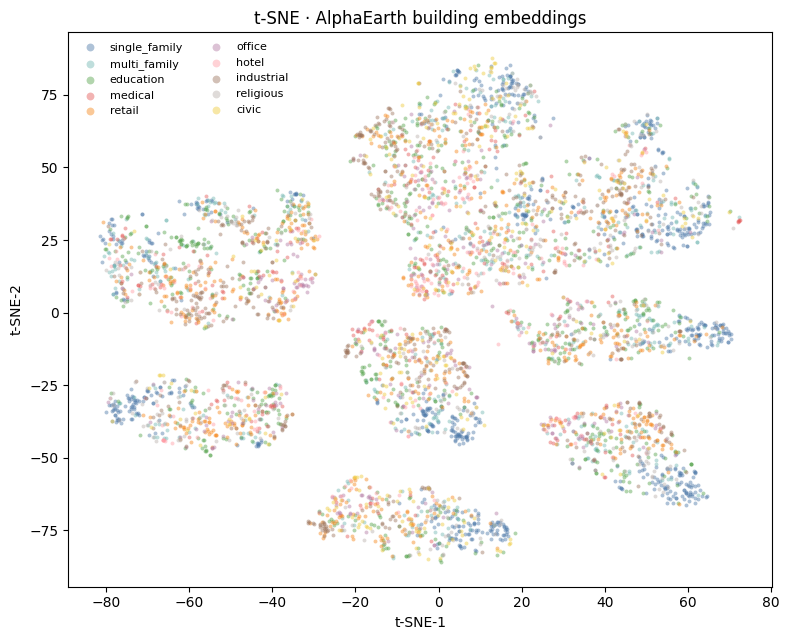

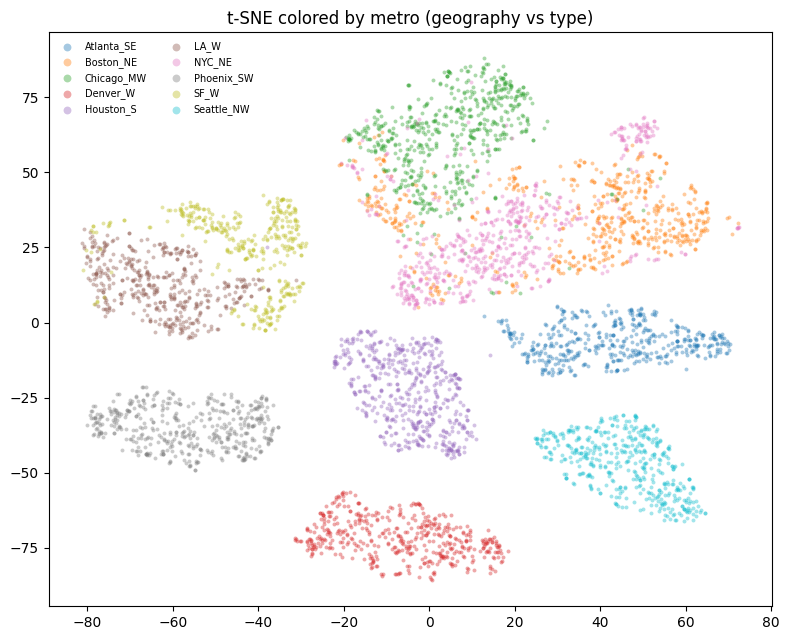

Wrote /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/embedding_eda/embedding_2d.parquet · t-SNE appended


In [8]:
# t-SNE on first 30 PCs (already computed). Full n=11,280 — a minute or two.
Z_tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    metric="euclidean",
    random_state=RANDOM_STATE,
).fit_transform(Z_pca[:, :30])

idx = rng.choice(len(df), size=min(5000, len(df)), replace=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
for lab in LABEL_ORDER:
    m = y[idx] == lab
    ax.scatter(
        Z_tsne[idx][m, 0],
        Z_tsne[idx][m, 1],
        s=8,
        alpha=0.45,
        c=COLORS[lab],
        label=lab,
        linewidths=0,
    )
ax.set_title("t-SNE · AlphaEarth building embeddings")
ax.set_xlabel("t-SNE-1")
ax.set_ylabel("t-SNE-2")
ax.legend(markerscale=2, fontsize=8, frameon=False, loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUT / "tsne_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
region_list = sorted(df["region"].unique())
cmap = plt.cm.tab10(np.linspace(0, 1, len(region_list)))
region_color = {r: cmap[i] for i, r in enumerate(region_list)}
for r in region_list:
    m = regions[idx] == r
    ax.scatter(
        Z_tsne[idx][m, 0],
        Z_tsne[idx][m, 1],
        s=8,
        alpha=0.4,
        c=[region_color[r]],
        label=r,
        linewidths=0,
    )
ax.set_title("t-SNE colored by metro (geography vs type)")
ax.legend(markerscale=2, fontsize=7, frameon=False, loc="best", ncol=2)
fig.tight_layout()
fig.savefig(OUT / "tsne_by_region.png", dpi=150, bbox_inches="tight")
plt.show()

# Append t-SNE coords to the 2-D cache
coord_path = OUT / "embedding_2d.parquet"
if coord_path.exists():
    coords = pd.read_parquet(coord_path)
    coords["tsne_1"] = Z_tsne[:, 0]
    coords["tsne_2"] = Z_tsne[:, 1]
else:
    coords = df[["id", "label", "region"]].copy()
    coords["tsne_1"] = Z_tsne[:, 0]
    coords["tsne_2"] = Z_tsne[:, 1]
coords.to_parquet(coord_path, index=False)
print("Wrote", coord_path, "· t-SNE appended")


**Takeaway — t-SNE.** Same story as UMAP: local clumps exist, but they do **not** line up with the 10 building types. Colored by metro, cities pull apart again. Geography is not a UMAP artifact — t-SNE sees it too.


## 3c. Overture footprints on AlphaEarth

False-color annual mosaic (`A01` / `A16` / `A32`, 2024) with **Overture building polygons** from the labeled dataset. Left: a dense Boston neighborhood. Right: zoom on one large footprint so the **10 m embedding pixel** (yellow) is visible. That pixel — not the polygon mean — is the current 64-D sample.


Earth Engine initialized · project = ee-kedarvaidya0504
Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/embedding_eda/overture_on_alphaearth.png · n=54 · window=(-71.06836,42.35323)–(-71.05636,42.36523)


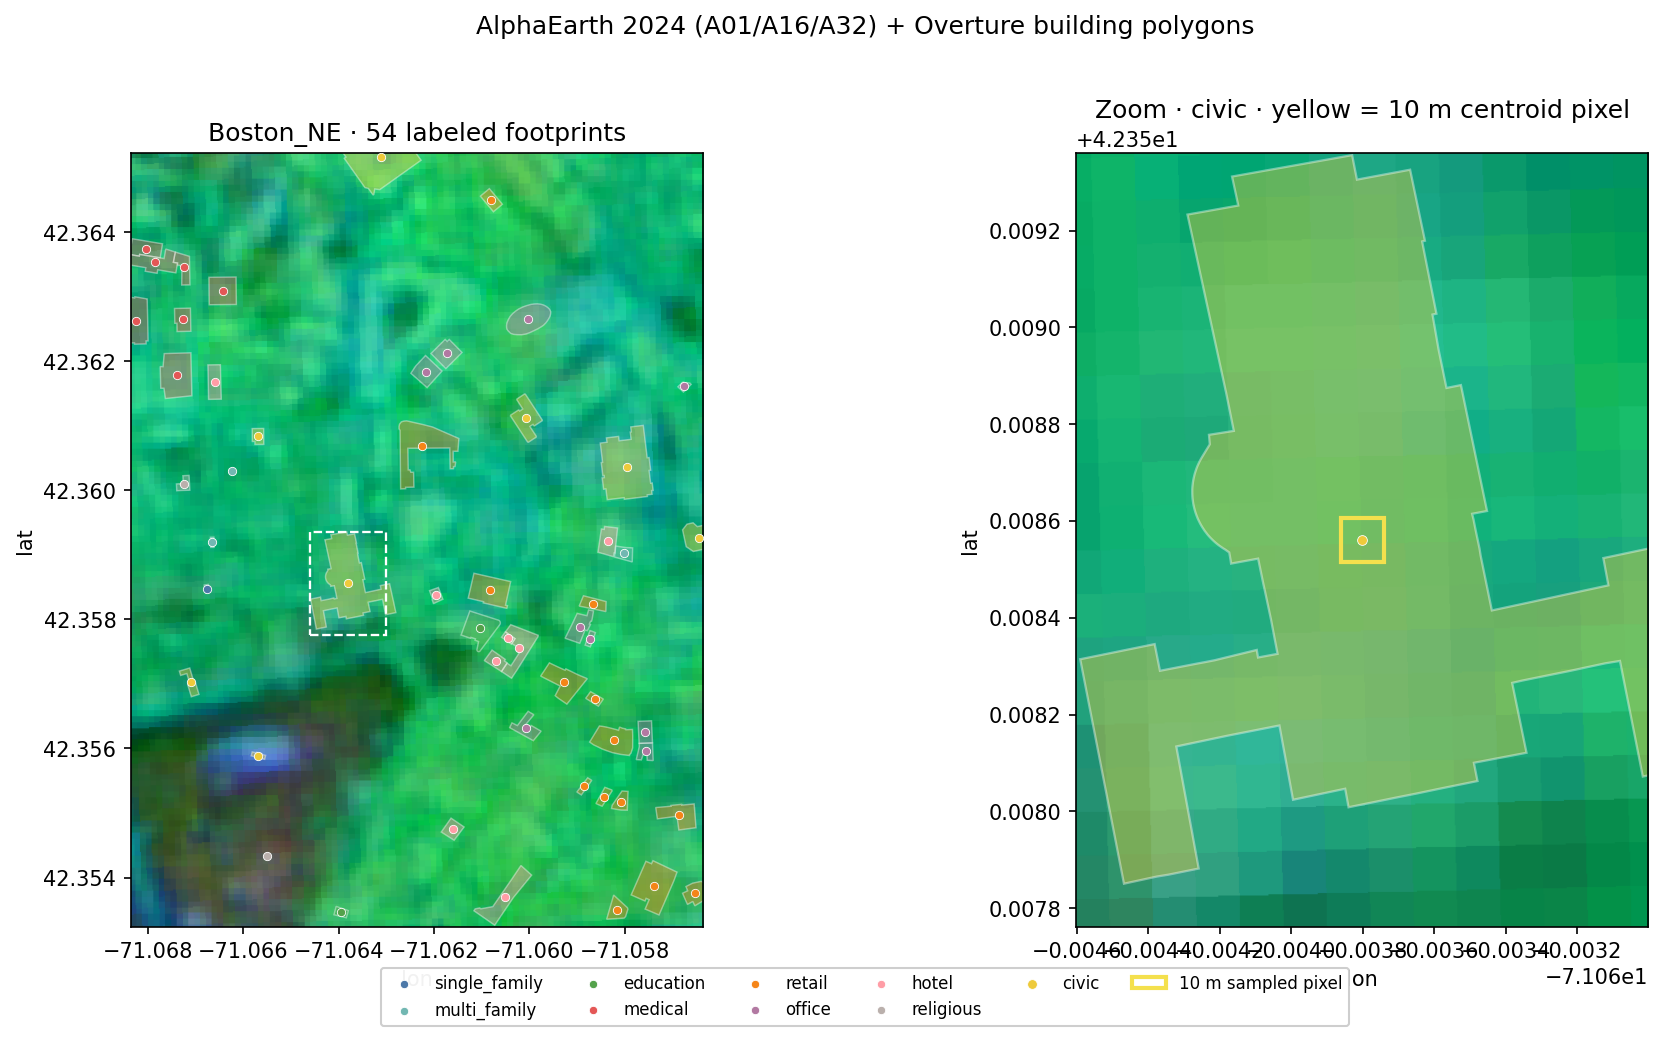

In [1]:
# Overture polygons on a false-color AlphaEarth thumbnail (needs EE)
import ee

EE_PROJECT = os.environ.get("EE_PROJECT", "ee-kedarvaidya0504")
EMBED_YEAR = 2024
VIZ_REGION = "Boston_NE"
HALF = 0.006  # ~1.3 km window
THUMB_DIM = 640


def init_ee(project: str) -> None:
    if not project or project == "YOUR_EE_PROJECT_ID":
        raise ValueError("Set EE_PROJECT to your Earth Engine Cloud project id.")
    try:
        ee.Initialize(project=project)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=project)
    print("Earth Engine initialized · project =", project)


def annual_embedding_image(year: int) -> ee.Image:
    return (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate(f"{year}-01-01", f"{year + 1}-01-01")
        .mosaic()
    )


init_ee(EE_PROJECT)

metro = df[df["region"] == VIZ_REGION].copy()
best = None
lons = np.linspace(metro.lon.min() + HALF, metro.lon.max() - HALF, 15)
lats = np.linspace(metro.lat.min() + HALF, metro.lat.max() - HALF, 15)
for cx_i in lons:
    for cy_i in lats:
        n = int(
            ((metro.lon.between(cx_i - HALF, cx_i + HALF))
             & (metro.lat.between(cy_i - HALF, cy_i + HALF))).sum()
        )
        if best is None or n > best[0]:
            best = (n, float(cx_i), float(cy_i))
_, cx, cy = best
zxmin, zxmax = cx - HALF, cx + HALF
zymin, zymax = cy - HALF, cy + HALF

img = annual_embedding_image(EMBED_YEAR)
rgb = img.select(["A01", "A16", "A32"]).visualize(min=-0.3, max=0.3)
thumb_url = rgb.getThumbURL(
    {
        "region": ee.Geometry.Rectangle([zxmin, zymin, zxmax, zymax]),
        "dimensions": THUMB_DIM,
        "format": "png",
    }
)
with urlreq.urlopen(thumb_url, timeout=120) as resp:
    thumb = np.array(Image.open(io.BytesIO(resp.read())))

pts = metro[
    (metro["lon"].between(zxmin, zxmax)) & (metro["lat"].between(zymin, zymax))
].copy()

# 10 m pixel in degrees at this latitude
dlat = 10.0 / 111_320.0
dlon = 10.0 / (111_320.0 * np.cos(np.deg2rad(cy)))
highlight = pts.loc[pts["area_m2_approx"].idxmax()] if "area_m2_approx" in pts.columns else pts.iloc[0]
hlon, hlat = float(highlight["lon"]), float(highlight["lat"])

# Tight zoom so the 10 m cell is readable (~180 m box)
ZOOM_HALF = 0.0008
zxmin2, zxmax2 = hlon - ZOOM_HALF, hlon + ZOOM_HALF
zymin2, zymax2 = hlat - ZOOM_HALF, hlat + ZOOM_HALF
thumb_url2 = rgb.getThumbURL(
    {
        "region": ee.Geometry.Rectangle([zxmin2, zymin2, zxmax2, zymax2]),
        "dimensions": THUMB_DIM,
        "format": "png",
    }
)
with urlreq.urlopen(thumb_url2, timeout=120) as resp:
    thumb_zoom = np.array(Image.open(io.BytesIO(resp.read())))

pts_zoom = metro[
    (metro["lon"].between(zxmin2, zxmax2)) & (metro["lat"].between(zymin2, zymax2))
].copy()


def _rings(geom):
    if geom.geom_type == "Polygon":
        return [geom.exterior]
    if geom.geom_type == "MultiPolygon":
        return [g.exterior for g in geom.geoms]
    return []


def _draw_overlay(ax, background, extent, buildings, show_pixel=False, lw=0.7):
    xmin, xmax, ymin, ymax = extent
    ax.imshow(background, extent=[xmin, xmax, ymin, ymax], origin="upper")
    for _, r in buildings.iterrows():
        geom = shapely_wkt.loads(r["wkt"])
        color = COLORS.get(r["label"], "#ffffff")
        for ring in _rings(geom):
            xs, ys = ring.xy
            ax.add_patch(
                MplPolygon(
                    np.column_stack([xs, ys]),
                    closed=True,
                    facecolor=color,
                    edgecolor="white",
                    linewidth=lw,
                    alpha=0.40,
                    zorder=2,
                )
            )
    for lab in LABEL_ORDER:
        p = buildings[buildings["label"] == lab]
        if p.empty:
            continue
        ax.scatter(
            p["lon"],
            p["lat"],
            s=22 if show_pixel else 16,
            c=COLORS[lab],
            label=lab,
            edgecolors="white",
            linewidths=0.4,
            zorder=4,
        )
    if show_pixel:
        ax.add_patch(
            Rectangle(
                (hlon - dlon / 2, hlat - dlat / 2),
                dlon,
                dlat,
                fill=False,
                edgecolor="#F4E04D",
                linewidth=2.0,
                zorder=5,
                label="10 m sampled pixel",
            )
        )
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    ax.set_aspect(1.0 / np.cos(np.deg2rad(0.5 * (ymin + ymax))))


fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.6))
_draw_overlay(axes[0], thumb, (zxmin, zxmax, zymin, zymax), pts)
axes[0].add_patch(
    Rectangle(
        (zxmin2, zymin2),
        zxmax2 - zxmin2,
        zymax2 - zymin2,
        fill=False,
        edgecolor="white",
        linewidth=1.1,
        linestyle="--",
        zorder=6,
    )
)
axes[0].set_title(f"{VIZ_REGION} · {len(pts)} labeled footprints")

_draw_overlay(axes[1], thumb_zoom, (zxmin2, zxmax2, zymin2, zymax2), pts_zoom, show_pixel=True, lw=1.1)
axes[1].set_title(f"Zoom · {highlight['label']} · yellow = 10 m centroid pixel")

handles, labels = [], []
for ax in axes:
    h, lab = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(lab)
uniq = dict(zip(labels, handles))
fig.legend(
    uniq.values(),
    uniq.keys(),
    loc="lower center",
    ncol=min(6, len(uniq)),
    fontsize=8,
    framealpha=0.95,
    bbox_to_anchor=(0.5, -0.02),
)
fig.suptitle(
    f"AlphaEarth {EMBED_YEAR} (A01/A16/A32) + Overture building polygons",
    y=1.01,
)
fig.tight_layout()
overlay_path = OUT / "overture_on_alphaearth.png"
fig.savefig(overlay_path, dpi=150, bbox_inches="tight")
print(
    f"Saved {overlay_path} · n={len(pts)} · "
    f"window=({zxmin:.5f},{zymin:.5f})–({zxmax:.5f},{zymax:.5f})"
)
plt.show()


**Takeaway — overlay.** Footprints sit on a spatially structured 10 m mosaic (texture, blocks, water). Each training vector is **one pixel at the centroid** (yellow box), so a large footprint still collapses to a single 10 m cell. That is why neighborhood / footprint-mean pooling is the next sampling lever.


## 4. Clustering

Unsupervised KMeans in embedding space vs true labels (ARI / NMI). High scores ⇒ category structure without supervision.


,k,silhouette_cosine,ARI,NMI
0,5,0.250,0.053,0.063
1,6,0.285,0.054,0.062
2,7,0.282,0.035,0.054
3,8,0.292,0.028,0.055
4,9,0.289,0.022,0.053
5,10,0.293,0.024,0.055
6,11,0.276,0.026,0.062
7,12,0.273,0.024,0.059
8,13,0.272,0.026,0.065
9,14,0.275,0.027,0.069


KMeans k=10 · ARI=0.023  NMI=0.053  silhouette=0.288


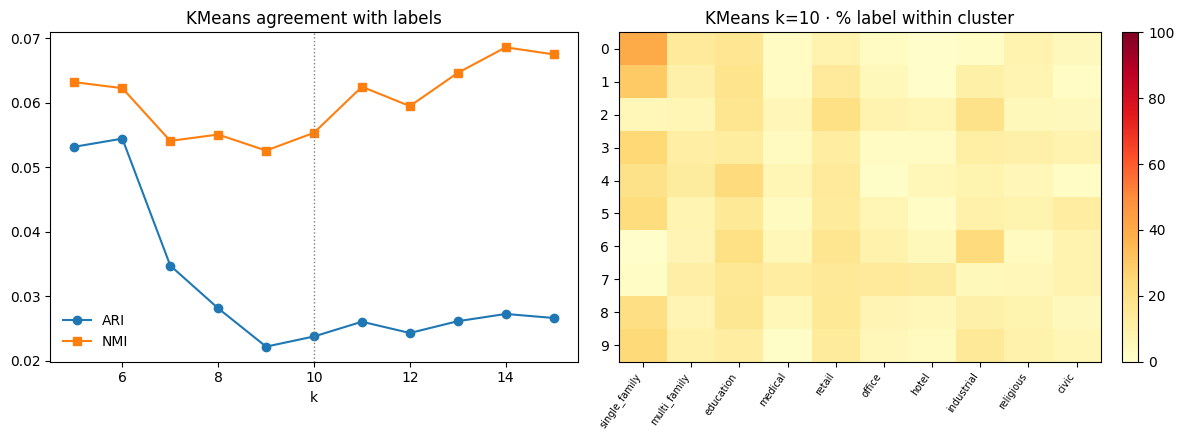

In [9]:
ks = list(range(5, 16))
rows = []
best = None
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    pred = km.fit_predict(X)
    sil = silhouette_score(X, pred, metric="cosine", sample_size=min(4000, len(X)), random_state=RANDOM_STATE)
    ari = adjusted_rand_score(y_id, pred)
    nmi = normalized_mutual_info_score(y_id, pred)
    rows.append({"k": k, "silhouette_cosine": sil, "ARI": ari, "NMI": nmi})
    if best is None or ari > best[0]:
        best = (ari, k, pred)

cluster_metrics = pd.DataFrame(rows)
cluster_metrics.to_csv(OUT / "clustering_metrics.csv", index=False)
display(cluster_metrics)

# Fixed k = n_classes
km10 = KMeans(n_clusters=len(LABEL_ORDER), n_init=20, random_state=RANDOM_STATE)
pred10 = km10.fit_predict(X)
ari10 = adjusted_rand_score(y_id, pred10)
nmi10 = normalized_mutual_info_score(y_id, pred10)
sil10 = silhouette_score(X, pred10, metric="cosine", sample_size=min(4000, len(X)), random_state=RANDOM_STATE)
print(f"KMeans k=10 · ARI={ari10:.3f}  NMI={nmi10:.3f}  silhouette={sil10:.3f}")

# Cluster ↔ label contingency (row-normalized)
cont = pd.crosstab(pd.Series(pred10, name="cluster"), pd.Series(y, name="label"))
cont = cont.reindex(columns=LABEL_ORDER, fill_value=0)
cont_pct = cont.div(cont.sum(axis=1), axis=0) * 100
cont_pct.to_csv(OUT / "kmeans10_label_mix_pct.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(cluster_metrics["k"], cluster_metrics["ARI"], marker="o", label="ARI")
axes[0].plot(cluster_metrics["k"], cluster_metrics["NMI"], marker="s", label="NMI")
axes[0].axvline(10, color="gray", ls=":", lw=1)
axes[0].set_xlabel("k")
axes[0].set_title("KMeans agreement with labels")
axes[0].legend(frameon=False)

im = axes[1].imshow(cont_pct.to_numpy(), aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
axes[1].set_xticks(range(len(LABEL_ORDER)))
axes[1].set_xticklabels(LABEL_ORDER, rotation=55, ha="right", fontsize=7)
axes[1].set_yticks(range(cont_pct.shape[0]))
axes[1].set_yticklabels(cont_pct.index)
axes[1].set_title("KMeans k=10 · % label within cluster")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(OUT / "clustering_overview.png", dpi=150, bbox_inches="tight")
plt.show()


**Takeaway — clustering.** Unsupervised KMeans barely agrees with building-use labels: ARI ≈ **0.02–0.05**, NMI ≈ **0.05–0.07** (near chance). At k=10, ARI=**0.023**, silhouette=**0.29**. Heatmap: every cluster is mixed; cluster 0 is ~40% single_family (majority class bleed), none is a pure function type. **You cannot discover the 10-way taxonomy by clustering AlphaEarth alone.**


## 5. Inter-class and intra-class distances

Cosine distance = \(1 - \cos\). Tight intra-class + large inter-class ⇒ separable categories.


,mean_intra,std_intra,n,mean_pairwise_intra,mean_pairwise_inter,separation_gap
label,,,,,,
single_family,0.186,0.088,1987,0.360,0.402,0.042
multi_family,0.174,0.073,1102,0.316,0.348,0.031
education,0.204,0.082,1840,0.379,0.372,-0.007
medical,0.175,0.093,594,0.322,0.358,0.036
retail,0.176,0.065,1616,0.305,0.347,0.042
office,0.177,0.072,756,0.315,0.360,0.045
hotel,0.166,0.072,539,0.300,0.356,0.056
industrial,0.187,0.074,1287,0.342,0.372,0.029
religious,0.187,0.084,802,0.331,0.351,0.020


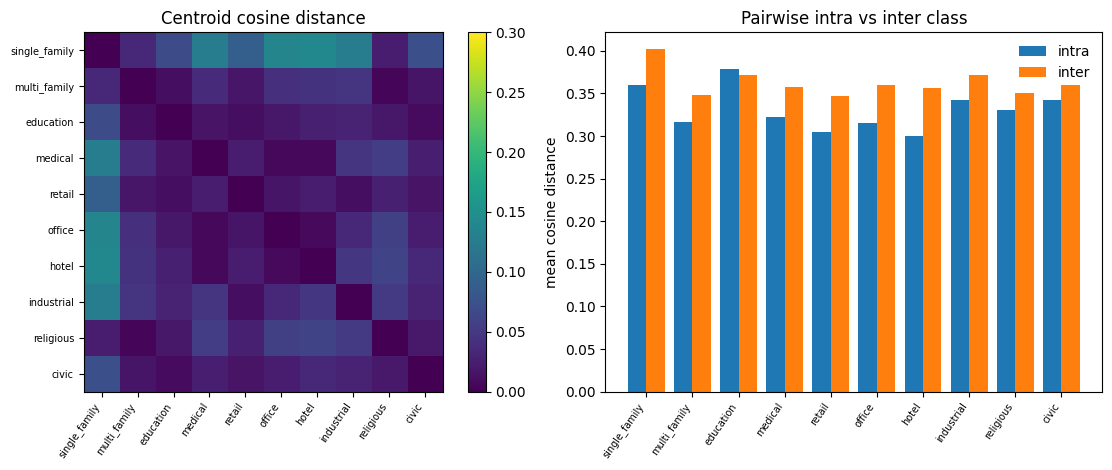

Mean separation gap (inter − intra): 0.031


In [10]:
def cosine_distance_matrix(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    # rows L2-normalized already
    return 1.0 - A @ B.T


# Class centroids
centroids = []
for lab in LABEL_ORDER:
    c = X[y == lab].mean(axis=0)
    c = c / np.linalg.norm(c)
    centroids.append(c)
C = np.vstack(centroids)

# Intra-class: mean distance of members to own centroid
intra = []
for i, lab in enumerate(LABEL_ORDER):
    Xi = X[y == lab]
    d = 1.0 - Xi @ C[i]
    intra.append({"label": lab, "mean_intra": float(d.mean()), "std_intra": float(d.std()), "n": len(Xi)})
intra_df = pd.DataFrame(intra).set_index("label")

# Inter-class: centroid–centroid distances
inter_cent = cosine_distance_matrix(C, C)
inter_df = pd.DataFrame(inter_cent, index=LABEL_ORDER, columns=LABEL_ORDER)

# Pairwise sample: mean distance within class vs to other classes
rng = np.random.default_rng(RANDOM_STATE)
pair_rows = []
for lab in LABEL_ORDER:
    idx_i = np.where(y == lab)[0]
    take = rng.choice(idx_i, size=min(200, len(idx_i)), replace=False)
    Xi = X[take]
    # within
    # sample pairs
    if len(take) >= 2:
        a = rng.choice(len(take), size=500, replace=True)
        b = rng.choice(len(take), size=500, replace=True)
        mask = a != b
        d_in = 1.0 - np.sum(Xi[a[mask]] * Xi[b[mask]], axis=1)
        mean_in = float(d_in.mean())
    else:
        mean_in = np.nan
    # to other classes (sample)
    idx_o = np.where(y != lab)[0]
    take_o = rng.choice(idx_o, size=min(500, len(idx_o)), replace=False)
    d_out = 1.0 - Xi @ X[take_o].T
    mean_out = float(d_out.mean())
    pair_rows.append(
        {
            "label": lab,
            "mean_pairwise_intra": mean_in,
            "mean_pairwise_inter": mean_out,
            "separation_gap": mean_out - mean_in,
        }
    )
pair_df = pd.DataFrame(pair_rows).set_index("label")

dist_summary = intra_df.join(pair_df)
dist_summary.to_csv(OUT / "distance_summary.csv")
inter_df.to_csv(OUT / "centroid_cosine_distance.csv")
display(dist_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
im = axes[0].imshow(inter_df.to_numpy(), cmap="viridis", vmin=0, vmax=max(0.3, inter_df.to_numpy().max()))
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
axes[0].set_xticklabels(LABEL_ORDER, rotation=55, ha="right", fontsize=7)
axes[0].set_yticklabels(LABEL_ORDER, fontsize=7)
axes[0].set_title("Centroid cosine distance")
fig.colorbar(im, ax=axes[0], fraction=0.046)

x = np.arange(len(LABEL_ORDER))
axes[1].bar(x - 0.2, dist_summary.loc[LABEL_ORDER, "mean_pairwise_intra"], width=0.4, label="intra")
axes[1].bar(x + 0.2, dist_summary.loc[LABEL_ORDER, "mean_pairwise_inter"], width=0.4, label="inter")
axes[1].set_xticks(x)
axes[1].set_xticklabels(LABEL_ORDER, rotation=55, ha="right", fontsize=7)
axes[1].set_ylabel("mean cosine distance")
axes[1].set_title("Pairwise intra vs inter class")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "distance_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mean separation gap (inter − intra):", f"{dist_summary['separation_gap'].mean():.3f}")


**Takeaway — distances.** Intra-class cosine distance is only slightly smaller than inter-class for most labels (mean gap **0.031**). Hotel has the largest gap (0.056); **education’s gap is negative** (−0.007) — those buildings are as close to other types as to each other. Class **centroids sit very close** (typical cosine distance ≪ 0.15). Prototype structure exists but is weak.


## 6. Nearest-neighbor retrieval

For each building, look up k nearest neighbors in embedding space. **Precision@k** = fraction of neighbors sharing the query label. Better than chance (\(1/C\) ≈ 0.10) ⇒ type signal.


Precision@k by class (chance ≈ 0.10):


k,1,5,10,20
label,,,,
single_family,0.765,0.689,0.660,0.627
multi_family,0.322,0.257,0.233,0.211
education,0.395,0.317,0.289,0.265
medical,0.355,0.263,0.226,0.189
retail,0.329,0.300,0.282,0.266
office,0.303,0.212,0.188,0.171
hotel,0.230,0.204,0.179,0.155
industrial,0.497,0.430,0.386,0.348
religious,0.171,0.128,0.120,0.117


Overall:


,k,precision_at_k,chance
0,1,0.410,0.100
11,5,0.347,0.100
22,10,0.321,0.100
33,20,0.297,0.100


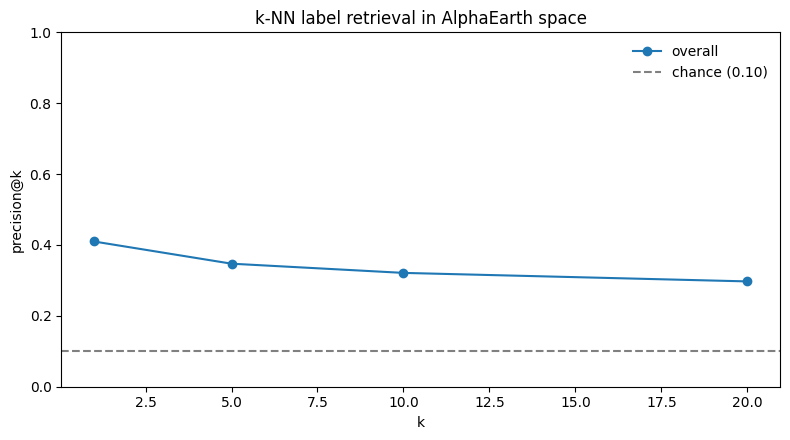

In [11]:
K_LIST = [1, 5, 10, 20]
nn = NearestNeighbors(n_neighbors=max(K_LIST) + 1, metric="cosine", algorithm="brute")
nn.fit(X)
dists, inds = nn.kneighbors(X, return_distance=True)
# column 0 is self
inds = inds[:, 1:]
dists = dists[:, 1:]

nn_rows = []
chance = 1.0 / len(LABEL_ORDER)
for k in K_LIST:
    # overall
    hit = (y[inds[:, :k]] == y[:, None]).mean(axis=1)
    overall = float(hit.mean())
    nn_rows.append({"k": k, "label": "(all)", "precision_at_k": overall, "chance": chance})
    for lab in LABEL_ORDER:
        m = y == lab
        nn_rows.append(
            {
                "k": k,
                "label": lab,
                "precision_at_k": float(hit[m].mean()),
                "chance": chance,
            }
        )

nn_df = pd.DataFrame(nn_rows)
nn_df.to_csv(OUT / "nn_precision_at_k.csv", index=False)

piv = nn_df[nn_df["label"] != "(all)"].pivot(index="label", columns="k", values="precision_at_k").reindex(LABEL_ORDER)
print("Precision@k by class (chance ≈ {:.2f}):".format(chance))
display(piv.round(3))
print("Overall:")
display(nn_df[nn_df["label"] == "(all)"][["k", "precision_at_k", "chance"]].round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
overall = nn_df[nn_df["label"] == "(all)"]
ax.plot(overall["k"], overall["precision_at_k"], marker="o", label="overall")
ax.axhline(chance, color="gray", ls="--", label=f"chance ({chance:.2f})")
ax.set_xlabel("k")
ax.set_ylabel("precision@k")
ax.set_title("k-NN label retrieval in AlphaEarth space")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "nn_precision.png", dpi=150, bbox_inches="tight")
plt.show()


**Takeaway — nearest neighbors.** This is the strongest unsupervised signal: overall Precision@1 = **0.41** vs chance **0.10** (4× chance). P@5 = 0.35, P@20 = 0.30. By class at k=1: single_family **0.76**, industrial **0.50**, education **0.40**; religious **0.17**, civic **0.20**, hotel **0.23**. Local neighbors preserve type much better than global clusters — good for kNN / metric learning, not for unsupervised discovery.


## 7. Embedding similarity analysis

Class-centroid cosine **similarity** matrix and a soft confusion from 1-NN predictions.


Leave-one-out 1-NN accuracy: 0.410  (chance ≈ 0.100)


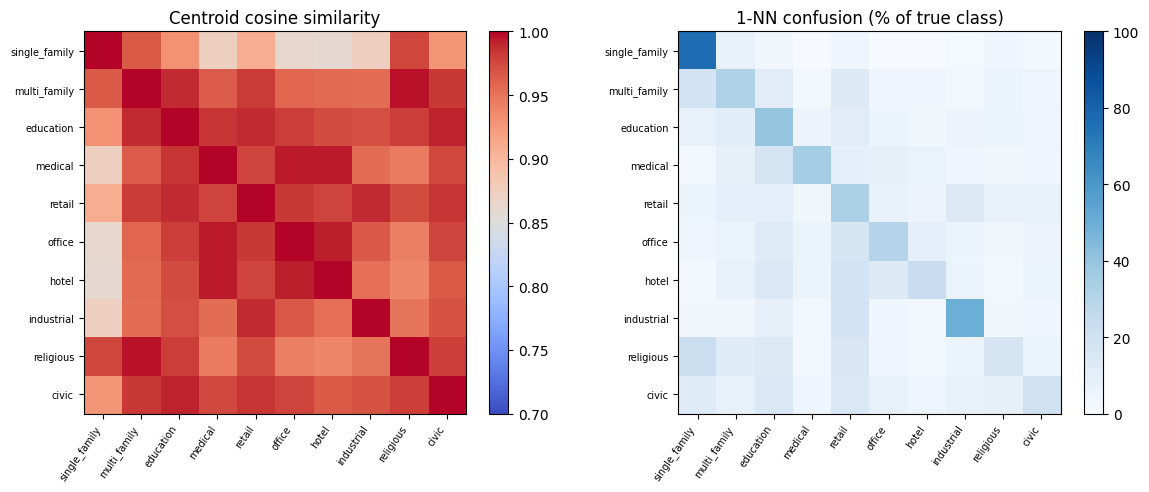

,single_family,multi_family,education,medical,retail,office,hotel,industrial,religious,civic
single_family,1.000,0.965,0.930,0.873,0.910,0.863,0.860,0.872,0.976,0.927
multi_family,0.965,1.000,0.989,0.964,0.981,0.958,0.956,0.955,0.996,0.983
education,0.930,0.989,1.000,0.984,0.989,0.981,0.973,0.971,0.981,0.992
medical,0.873,0.964,0.984,1.000,0.978,0.993,0.994,0.955,0.946,0.975
retail,0.910,0.981,0.989,0.978,1.000,0.983,0.977,0.989,0.974,0.985
office,0.863,0.958,0.981,0.993,0.983,1.000,0.992,0.967,0.943,0.978
hotel,0.860,0.956,0.973,0.994,0.977,0.992,1.000,0.953,0.939,0.965
industrial,0.872,0.955,0.971,0.955,0.989,0.967,0.953,1.000,0.949,0.970
religious,0.976,0.996,0.981,0.946,0.974,0.943,0.939,0.949,1.000,0.980
civic,0.927,0.983,0.992,0.975,0.985,0.978,0.965,0.970,0.980,1.000


In [12]:
sim = C @ C.T
sim_df = pd.DataFrame(sim, index=LABEL_ORDER, columns=LABEL_ORDER)
sim_df.to_csv(OUT / "centroid_cosine_similarity.csv")

# 1-NN "classifier" confusion (leave-one-out via neighbors already excluding self)
pred_1nn = y[inds[:, 0]]
conf = pd.crosstab(
    pd.Series(y, name="true"),
    pd.Series(pred_1nn, name="pred_1nn"),
    normalize="index",
).reindex(index=LABEL_ORDER, columns=LABEL_ORDER) * 100
conf.to_csv(OUT / "nn1_confusion_pct.csv")

acc_1nn = float((pred_1nn == y).mean())
print(f"Leave-one-out 1-NN accuracy: {acc_1nn:.3f}  (chance ≈ {chance:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(sim_df.to_numpy(), cmap="coolwarm", vmin=0.7, vmax=1.0)
axes[0].set_xticks(range(10))
axes[0].set_yticks(range(10))
axes[0].set_xticklabels(LABEL_ORDER, rotation=55, ha="right", fontsize=7)
axes[0].set_yticklabels(LABEL_ORDER, fontsize=7)
axes[0].set_title("Centroid cosine similarity")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(conf.to_numpy(), cmap="Blues", vmin=0, vmax=100)
axes[1].set_xticks(range(10))
axes[1].set_yticks(range(10))
axes[1].set_xticklabels(LABEL_ORDER, rotation=55, ha="right", fontsize=7)
axes[1].set_yticklabels(LABEL_ORDER, fontsize=7)
axes[1].set_title("1-NN confusion (% of true class)")
fig.colorbar(im1, ax=axes[1], fraction=0.046)
fig.tight_layout()
fig.savefig(OUT / "similarity_and_nn1.png", dpi=150, bbox_inches="tight")
plt.show()
display(sim_df.round(3))


**Takeaway — similarity & 1-NN.** Leave-one-out 1-NN accuracy = **41%** (chance 10%). Centroid similarities are high across the board (often **>0.95**); single_family is the most distinct. 1-NN confusions match intuition: religious → single_family, hotel → retail/office, civic mixed everywhere, multi_family leaks into single_family. Fine-grained commercial/civic types are not linearly (or even locally) clean.


## 8. Verdict

Interpret against the brief: *are functional building characteristics encoded in AlphaEarth before complex supervised models?*


In [13]:
summary = {
    "n": int(len(df)),
    "dim": 64,
    "pca_var_pc12": float(var[:2].sum()),
    "pca_var_pc1_10": float(var[:10].sum()),
    "kmeans_k10_ARI": float(ari10),
    "kmeans_k10_NMI": float(nmi10),
    "kmeans_k10_silhouette_cosine": float(sil10),
    "mean_separation_gap": float(dist_summary["separation_gap"].mean()),
    "nn_precision_at_1": float(nn_df[(nn_df["label"] == "(all)") & (nn_df["k"] == 1)]["precision_at_k"].iloc[0]),
    "nn_precision_at_5": float(nn_df[(nn_df["label"] == "(all)") & (nn_df["k"] == 5)]["precision_at_k"].iloc[0]),
    "nn1_accuracy": float(acc_1nn),
    "chance_precision": float(chance),
    "umap_resi_boundary_f1_mean": float(f1_series.mean()) if "f1_series" in globals() else None,
    "umap_resi_boundary_f1_by_region": (
        {k: float(v) for k, v in f1_series.items()} if "f1_series" in globals() else None
    ),
}

# Heuristic read-out
signal = summary["nn_precision_at_1"] > 1.5 * chance
summary["interpretation"] = (
    "AlphaEarth centroids carry measurable building-type signal (NN ≫ chance; modest cluster agreement), "
    "but classes heavily overlap — enough to justify supervised baselines, not enough to expect strong "
    "unsupervised discovery of all 10 functional types."
    if signal
    else "Little evidence of type structure above chance in centroid embeddings; revisit pooling / labels."
)

with open(OUT / "eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nWrote outputs →", OUT)
for p in sorted(OUT.iterdir()):
    print(f"  {p.name}")


{
  "n": 11280,
  "dim": 64,
  "pca_var_pc12": 0.3322752339382665,
  "pca_var_pc1_10": 0.8001813658448709,
  "kmeans_k10_ARI": 0.02252093644590398,
  "kmeans_k10_NMI": 0.053436726832857155,
  "kmeans_k10_silhouette_cosine": 0.28776301831557943,
  "mean_separation_gap": 0.03117312886400589,
  "nn_precision_at_1": 0.4098404255319149,
  "nn_precision_at_5": 0.3471808510638298,
  "nn1_accuracy": 0.4098404255319149,
  "chance_precision": 0.1,
  "interpretation": "AlphaEarth centroids carry measurable building-type signal (NN \u226b chance; modest cluster agreement), but classes heavily overlap \u2014 enough to justify supervised baselines, not enough to expect strong unsupervised discovery of all 10 functional types."
}

Wrote outputs → /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/embedding_eda
  centroid_cosine_distance.csv
  centroid_cosine_similarity.csv
  clustering_metrics.csv
  clustering_overview.png
  distance_analysis.png
  distance_summary.csv
  eda_summary.json
  emb

**Verdict.** AlphaEarth **does encode some building-type signal** (1-NN 41% vs 10% chance), but classes **heavily overlap** and **geography is entangled** with type. Within each metro, residential vs non-residential is partly visible even in the 2D UMAP plane (mean in-UMAP LR F1 ≈ **0.71**). Enough to justify a supervised baseline; **not** enough to expect unsupervised discovery of all 10 functional types, or to match street-view / VHR SOTA (high 80s–90s).


### Overall takeaways

1. **There is type signal, but it is local not global.** 1-NN / Precision@1 is **41%** (4× chance). KMeans ARI is ~**0.02**. Neighbors know the label better than clusters do.
2. **Geography is baked into the 10 m embeddings.** UMAP **and t-SNE** separate metros, not types. Expect LORO accuracy to drop vs pooled holdout. Within each metro, residential vs non-residential is still partly linearly separable in the 2D UMAP plane (mean in-UMAP F1 ≈ **0.71**).
3. **Single-family (and industrial) stand out; civic / religious / hotel do not.** P@1: SF 0.76, industrial 0.50 vs religious 0.17, civic 0.20.
4. **Class centroids almost coincide.** Pairwise centroid cosine is often >0.95, so a “mean building type” vector is a weak discriminator. Education even has a **negative** intra/inter gap.
5. **Implication for models.** A simple supervised classifier can beat chance; it will not hit multi-modal SOTA. Next levers: footprint-mean pooling, neighborhood context, binary residential first, then multi-class.
6. **Sampling is a single 10 m pixel.** The Overture overlay shows footprints sitting on the mosaic, but each vector is the centroid cell only — large buildings still collapse to one AlphaEarth pixel.

| Signal | What we saw | Means |
|---|---|---|
| PCA PC1–2 mixed | 33% var; one cloud | No easy linear 2-D separation |
| UMAP islands = cities | Metro coloring clean, labels mixed | Place ≫ type |
| UMAP resi boundary | Mean in-UMAP LR F1 ≈ 0.71 (NYC 0.59 → Houston 0.79) | Binary resi cut exists within metros |
| KMeans vs labels | ARI 0.02, NMI 0.05 | Unsupervised discovery fails |
| Intra vs inter | mean gap 0.03 | Weak prototype structure |
| Precision@1 | 0.41 vs 0.10 chance | Local neighborhoods preserve type |
| 1-NN confusions | SF/industrial OK; civic/hotel/religious fail | Hard pairs for satellite-only features |


we want (../../outputs/week2_cnn_bbox/umap_cnn_by_region_panels_residential_boundary.png) style analysis for the embeddings umap in this notebook